# M115 Lab 1: Phishing URL Detection — EDA, Parameterized Logistic Regression & SHAP Explainability

---

## 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027

---

## 🧭 Lab Overview & Solution Key

This notebook contains the assignment of **Lab 1** on the **[PhiUSIIL Phishing URL Dataset](https://www.kaggle.com/datasets/kaggleprollc/phishing-url-websites-dataset-phiusiil/data)** (*235,795 URLs and 56 lexical, network, and HTML features*, Prasad & Chandra, *Computers & Security*, 2024).

### 📋 Table of Contents
* **1 - Importing Packages & Loading Data**
* **2 - Part 1: Security-Oriented Exploratory Data Analysis (EDA)**
  * 2.1 Data Quality Inspection & SOC Target Alignment (Exercise 1)
  * 2.2 Class Balance, Numerical Distributions & Binary Security Indicators (Exercise 2)
  * 2.3 Identifier Cleanup & Feature–Target Correlations (Exercise 3)
  * *Part 1 Reflection Questions*
* **3 - Part 2: Zero-Data Leakage Preprocessing & Standardization**
  * 3.1 Stratified 75/25 Split & Training-Only StandardScaler (Exercise 4)
  * *Part 2 Reflection Questions*
* **4 - Part 3: Parameterized Logistic Regression & Interpretability**
  * 4.1 Comparing 5 Logistic Regression Configurations (Exercise 5)
  * 4.2 L1 Regularization Path & Feature Selection (Exercise 6)
  * 4.3 Interpreting Coefficients ($w_j$) and Odds Ratios ($e^{w_j}$) (Exercise 7)
  * *Part 3 Reflection Questions*
* **5 - Part 4: Explainable AI (SHAP) & SOC Threshold Analysis**
  * 5.1 Global Explanations with `shap.LinearExplainer` (Exercise 8)
  * 5.2 Local SOC Alert Triage: TP, TN, and FP Waterfall Plots (Exercise 9)
  * 5.3 Operational Decision Threshold Tuning ($\tau \in \{0.20, 0.50, 0.85\}$) (Exercise 10)
  * *Part 4 Reflection Questions*
* **6 - Conclusion & SOC Engineering Synthesis**

### Before running
Keep `M115_Lab1_Solution.ipynb` and `PhiUSIIL_Phishing_URL_Dataset.csv` in the same folder. Install the required packages if needed:

```bash
pip install numpy pandas matplotlib seaborn scikit-learn shap ipykernel
```

Then select **Kernel → Restart & Run All**. The SHAP and L1 regularization exercises may take several minutes because the full dataset contains 235,795 URLs.

---
## 1 - Importing Packages & Loading Data

Run the cell below to import the required libraries and configure reproducibility (`SEED = 42`):

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score
)
import shap

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 4.5)
SEED = 42
np.random.seed(SEED)

---
## 2 - Part 1: Security-Oriented Exploratory Data Analysis (EDA)

### 2.1 Data Quality Inspection & SOC Target Alignment (Exercise 1)

First, we load `PhiUSIIL_Phishing_URL_Dataset.csv` and inspect its shape, data types, missing values, duplicate rows, and summary statistics across key numerical features (`URLLength`, `LineOfCode`, `CharContinuationRate`, `NoOfSelfRef`).

In [17]:
# Load dataset and inspect data quality
df = pd.read_csv('PhiUSIIL_Phishing_URL_Dataset.csv')
print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isna().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("\nDataset Info:")
df.info()

display(df[['FILENAME', 'URL', 'URLLength', 'LineOfCode', 'IsHTTPS', 'HasPasswordField', 'NoOfSelfRef', 'label']].head(5))
display(df[['URLLength', 'LineOfCode', 'CharContinuationRate', 'NoOfSelfRef']].describe().round(2))

Dataset Shape: (235795, 56)
Total Missing Values: 0
Duplicate Rows: 0

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12

,FILENAME,URL,URLLength,LineOfCode,IsHTTPS,HasPasswordField,NoOfSelfRef,label
0,521848.txt,https://www.southbankmosaics.com,31,558,1,0,119,1
1,31372.txt,https://www.uni-mainz.de,23,618,1,0,39,1
2,597387.txt,https://www.voicefmradio.co.uk,29,467,1,0,42,1
3,554095.txt,https://www.sfnmjournal.com,26,6356,1,0,22,1
4,151578.txt,https://www.rewildingargentina.org,33,6089,1,0,72,1


,URLLength,LineOfCode,CharContinuationRate,NoOfSelfRef
count,235795.00,235795.00,235795.00,235795.00
mean,34.57,1141.90,0.85,65.07
std,41.31,3419.95,0.22,176.69
min,13.00,2.00,0.00,0.00
25%,23.00,18.00,0.68,0.00
50%,27.00,429.00,1.00,12.00
75%,34.00,1277.00,1.00,88.00
max,6097.00,442666.00,1.00,27397.00


> **⚠️ Critical Cyber Label Warning in PhiUSIIL:**  
> In the raw CSV file, **`label = 1` denotes Legitimate (Benign)** and **`label = 0` denotes Phishing (Malicious)**.  
> In a SOC, the positive class (`1`) **must always represent the attack** (`Phishing = 1`, `Benign = 0`) so that True Positives (TP), Precision, and Recall measure our threat detection capability.

### Exercise 1

In [18]:
# EXERCISE 1: Data Quality & SOC Target Alignment (1 = Phishing, 0 = Benign)

### START CODE HERE ### (≈ 2 lines of code)
df['IsPhishing'] = 1 - df['label']
phishing_ratio = df['IsPhishing'].mean()
### END CODE HERE ###

print(f"Phishing URLs (1): {(df['IsPhishing'] == 1).sum():,}")
print(f"Legitimate URLs (0): {(df['IsPhishing'] == 0).sum():,}")
print(f"Phishing Proportion: {phishing_ratio * 100:.2f}%")
print("\nNormalized Class Proportions:")
print(df['IsPhishing'].value_counts(normalize=True).round(4))

Phishing URLs (1): 100,945
Legitimate URLs (0): 134,850
Phishing Proportion: 42.81%

Normalized Class Proportions:
IsPhishing
0    0.5719
1    0.4281
Name: proportion, dtype: float64


---
### 2.2 Class Balance, Numerical Distributions & Binary Security Indicators (Exercise 2)

We compare legitimate (`0`) and phishing (`1`) URLs across class balance, continuous lexical/HTML features (`URLLength`, `CharContinuationRate`, `NoOfSelfRef`), and binary security indicators (`IsHTTPS`, `HasPasswordField`, `HasCopyrightInfo`, `HasSocialNet`).

### Exercise 2

Percentage (%) of URLs presenting each binary indicator per class (0=Benign, 1=Phishing):


,IsHTTPS,HasPasswordField,HasCopyrightInfo,HasSocialNet
IsPhishing,,,,
0,100.00,13.85,80.82,79.46
1,49.22,5.39,5.73,0.51


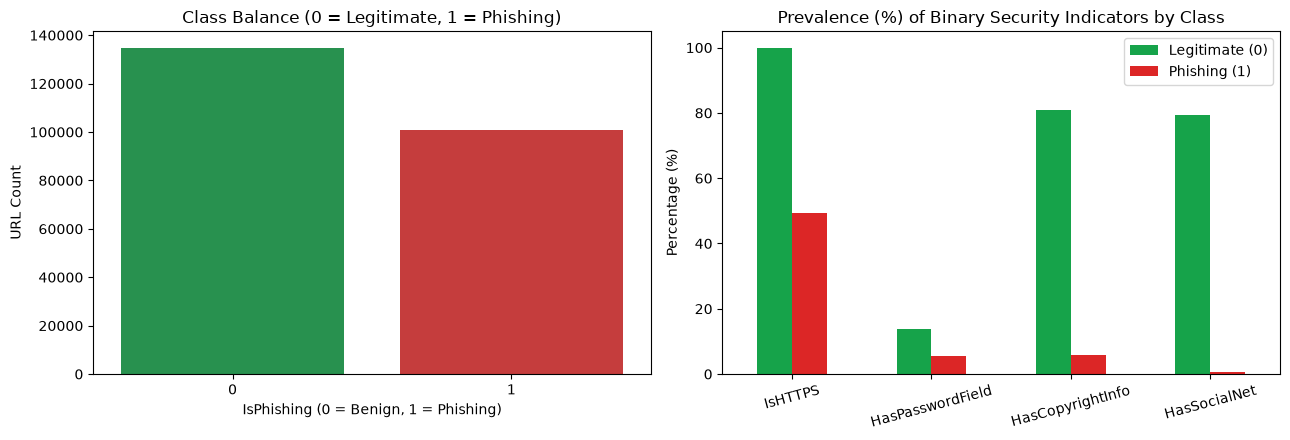

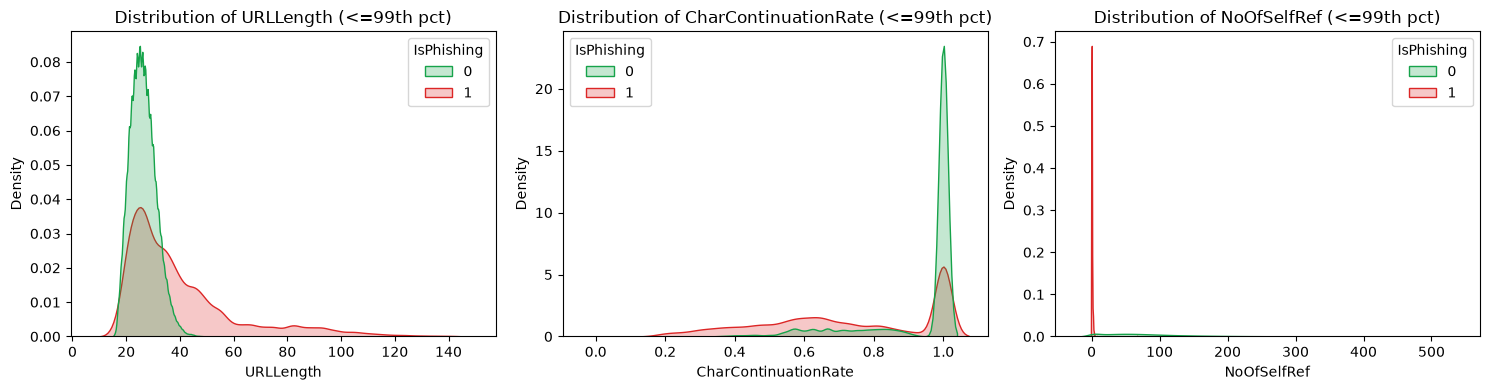

In [19]:
# EXERCISE 2: Visualizing Distributions and Binary Security Indicators
binary_cols = ['IsHTTPS', 'HasPasswordField', 'HasCopyrightInfo', 'HasSocialNet']
num_cols = ['URLLength', 'CharContinuationRate', 'NoOfSelfRef']

### START CODE HERE ### (≈ 1 line of code)
binary_stats = df.groupby('IsPhishing')[binary_cols].mean() * 100
### END CODE HERE ###

print("Percentage (%) of URLs presenting each binary indicator per class (0=Benign, 1=Phishing):")
display(binary_stats.round(2))

# 1. Class Balance & Binary Indicators Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x='IsPhishing', hue='IsPhishing', ax=axes[0], palette=['#16a34a', '#dc2626'], legend=False)
axes[0].set_title("Class Balance (0 = Legitimate, 1 = Phishing)")
axes[0].set_xlabel("IsPhishing (0 = Benign, 1 = Phishing)")
axes[0].set_ylabel("URL Count")

binary_stats.T.plot(kind='bar', ax=axes[1], color=['#16a34a', '#dc2626'])
axes[1].set_title("Prevalence (%) of Binary Security Indicators by Class")
axes[1].set_ylabel("Percentage (%)")
axes[1].set_xticklabels(binary_cols, rotation=15)
axes[1].legend(["Legitimate (0)", "Phishing (1)"])
plt.tight_layout()
plt.show()

# 2. Numerical Distributions (KDE Plots clipped at 99th percentile for readability)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(num_cols):
    upper_clip = df[col].quantile(0.99)
    sns.kdeplot(
        data=df[df[col] <= upper_clip],
        x=col,
        hue='IsPhishing',
        common_norm=False,
        fill=True,
        palette=['#16a34a', '#dc2626'],
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {col} (<=99th pct)")
plt.tight_layout()
plt.show()

---
### 2.3 Identifier Cleanup & Feature–Target Correlations (Exercise 3)

We drop non-generalizable raw text strings (`FILENAME`, `URL`, `Domain`, `TLD`, `Title`), the old `label`, and the pre-computed `URLSimilarityIndex` score so our model learns from genuine lexical and HTML indicators. Then we compute the Pearson correlation of each numerical feature with `IsPhishing`.

### Exercise 3

Shape of X: (235795, 49) | Shape of y: (235795,)


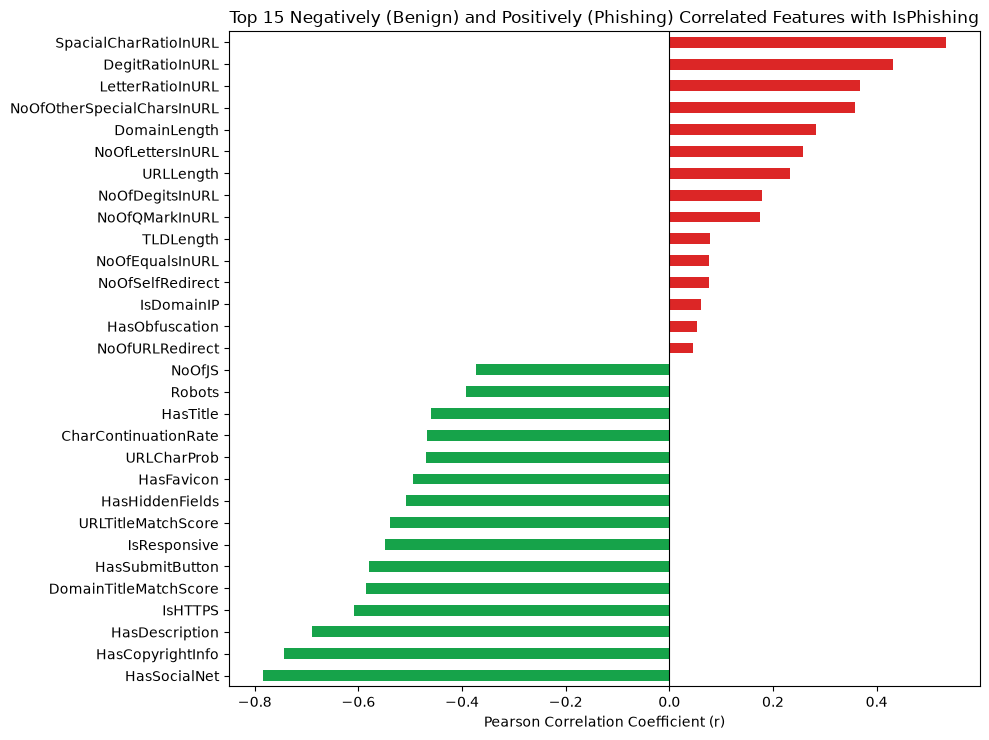

In [20]:
# EXERCISE 3: Constructing X, y and Analyzing Target Correlations
cols_to_drop = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title', 'label', 'IsPhishing', 'URLSimilarityIndex']

### START CODE HERE ### (≈ 3 lines of code)
X = df.drop(columns=cols_to_drop).select_dtypes(include=[np.number]).copy()
y = df['IsPhishing'].astype(int)
correlations = X.corrwith(y).sort_values()
### END CODE HERE ###

print("Shape of X:", X.shape, "| Shape of y:", y.shape)

# Plot Top 15 Negatively and Top 15 Positively Correlated Features
top_corr = pd.concat([correlations.head(15), correlations.tail(15)])
plt.figure(figsize=(10, 7.5))
colors = ['#16a34a' if c < 0 else '#dc2626' for c in top_corr.values]
top_corr.plot(kind='barh', color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title("Top 15 Negatively (Benign) and Positively (Phishing) Correlated Features with IsPhishing")
plt.xlabel("Pearson Correlation Coefficient (r)")
plt.tight_layout()
plt.show()

---
### 💡 Part 1 Reflection Questions

1. **HTTPS on phishing sites:** The exact percentage is shown in the `binary_stats` table under `IsHTTPS` for class `1` (Phishing). HTTPS only encrypts the connection; it does not validate that a website is trustworthy. Attackers can also obtain free TLS certificates, so the rule “If HTTPS then Legitimate” would miss phishing sites.

2. **Internal links and password fields:** Phishing pages are often short-lived replicas designed around one action, such as collecting credentials. They therefore may contain few internal navigation links while including a password field to capture login information.

3. **Raw identifiers:** Keeping `URL`, `Domain`, `FILENAME` or similar text identifiers can let the model memorize specific domains or strings instead of learning general phishing behavior. This causes overfitting and poor generalization to new URLs; it can also create an unnecessarily high-cardinality, fragile feature space.

---
## 3 - Part 2: Zero-Data Leakage Preprocessing & Standardization

### 3.1 Stratified 75/25 Split & Training-Only StandardScaler (Exercise 4)

We apply the **SecMLOps Golden Rule**: split the dataset into training (75%) and test (25%) subsets *before* computing Z-score normalization parameters ($\mu_{\text{train}}, \sigma_{\text{train}}$).

### Exercise 4

In [21]:
# EXERCISE 4: Stratified Split and Leakage-Free Standardization

### START CODE HERE ### (≈ 4 lines of code)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
### END CODE HERE ###

# Retain column names and indices for weight and SHAP interpretability
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled  = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

print("Train shape:", X_train_scaled.shape, "| Test shape:", X_test_scaled.shape)
print("Mean of X_train_scaled (URLLength):", round(X_train_scaled['URLLength'].mean(), 4))
print("Std of X_train_scaled (URLLength):", round(X_train_scaled['URLLength'].std(), 4))

Train shape: (176846, 49) | Test shape: (58949, 49)
Mean of X_train_scaled (URLLength): -0.0
Std of X_train_scaled (URLLength): 1.0


---
### 💡 Part 2 Reflection Questions

1. `LineOfCode` can reach values above 10,000, whereas `IsHTTPS` is only 0 or 1. Without standardization, the large-scale variables can dominate the regularization penalty and optimization. L1/L2 would then penalize coefficients unevenly because of their units rather than their predictive value.

2. If the scaler is fitted before splitting, its mean and standard deviation are calculated using both training and test observations. Information about the test distribution therefore influences preprocessing during training. This is preprocessing data leakage and makes the evaluation less independent. Fit only on `X_train`, then use that fitted scaler to transform `X_test`.

---
## 4 - Part 3: Parameterized Logistic Regression & Interpretability

### 4.1 Comparing 5 Logistic Regression Configurations (Exercise 5)

We train and evaluate the five specified Logistic Regression configurations on `X_train_scaled` and `X_test_scaled`:
* **M1: Unregularized (`penalty=None`)**
* **M2: Strong L2 Ridge (`penalty='l2', C=0.001`)**
* **M3: Standard L2 Ridge (`penalty='l2', C=1.0`)**
* **M4: Sparse L1 Lasso (`penalty='l1', C=0.01`)**
* **M5: SOC Weighted (`penalty='l2', C=1.0, class_weight='balanced'`)**

### Exercise 5

In [22]:
# EXERCISE 5: Training and Comparing 5 Logistic Regression Configurations
configurations = {
    "M1: Unregularized (None)": LogisticRegression(penalty=None, solver='lbfgs', max_iter=500, random_state=SEED),
    "M2: Strong L2 Ridge (C=0.001)": LogisticRegression(penalty='l2', C=0.001, solver='lbfgs', max_iter=500, random_state=SEED),
    "M3: Standard L2 Ridge (C=1.0)": LogisticRegression(penalty='l2', C=1.0, solver='lbfgs', max_iter=500, random_state=SEED),
    "M4: Sparse L1 Lasso (C=0.01)": LogisticRegression(penalty='l1', C=0.01, solver='liblinear', max_iter=500, random_state=SEED),
    "M5: SOC Weighted (balanced)": LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', solver='lbfgs', max_iter=500, random_state=SEED),
}

results = []
for name, model in configurations.items():
    ### START CODE HERE ### (≈ 5 lines of code)
    model.fit(X_train_scaled, y_train)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    y_pred = (y_prob >= 0.50).astype(int)
    w = model.coef_[0]
    n_zero_weights = int(np.sum(np.abs(w) < 1e-4))
    ### END CODE HERE ###

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    results.append({
        "Model": name,
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall (TPR)": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4),
        "PR-AUC": round(average_precision_score(y_test, y_prob), 4),
        "False Alarms (FP)": int(fp),
        "Missed Phish (FN)": int(fn),
        "Zeroed Weights (Sparsity)": f"{n_zero_weights} / {len(w)}"
    })

results_df = pd.DataFrame(results)
display(results_df)

c:\Users\Mohamed\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Mohamed\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Mohamed\anaconda3\Lib\site-packages\sklearn\lin

,Model,Precision,Recall (TPR),F1-Score,PR-AUC,False Alarms (FP),Missed Phish (FN),Zeroed Weights (Sparsity)
0,M1: Unregularized (None),0.9996,0.9990,0.9993,1.0,11,25,0 / 49
1,M2: Strong L2 Ridge (C=0.001),0.9985,0.9958,0.9971,1.0,39,105,0 / 49
2,M3: Standard L2 Ridge (C=1.0),0.9996,0.9989,0.9992,1.0,10,28,0 / 49
3,M4: Sparse L1 Lasso (C=0.01),0.9993,0.9971,0.9982,1.0,18,72,24 / 49
4,M5: SOC Weighted (balanced),0.9995,0.9990,0.9992,1.0,13,25,0 / 49


---
### 4.2 L1 Regularization Path & Feature Selection (Exercise 6)

We vary `C` across `[0.002, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]` with `penalty='l1'` (`solver='liblinear'`) and plot the number of retained features ($|w_j| \ge 10^{-4}$) as a function of `C` on a logarithmic scale.

### Exercise 6

c:\Users\Mohamed\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Mohamed\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\Mohamed\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ra

,C,Active_Features,Zeroed_Features
0,0.002,25,24
1,0.010,25,24
2,0.050,25,24
3,0.100,25,24
4,0.500,25,24
5,1.000,25,24
6,5.000,25,24


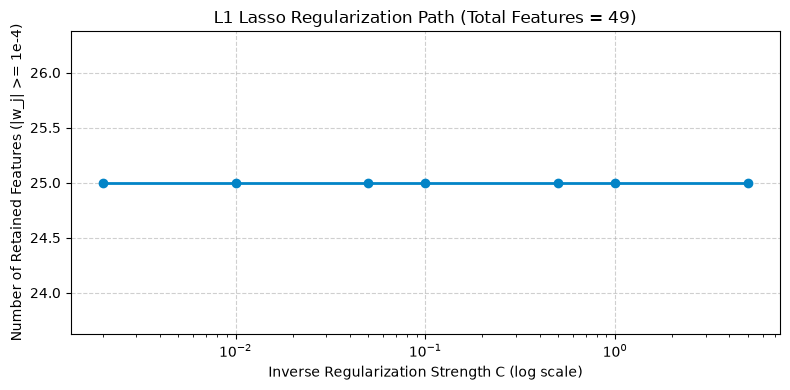

In [23]:
# EXERCISE 6: L1 Regularization Path (Number of Active Features vs. C)
C_values = [0.002, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
active_features_count = []

for c_val in C_values:
    ### START CODE HERE ### (≈ 3 lines of code)
    m_l1 = LogisticRegression(penalty='l1', C=0.01, solver='liblinear', max_iter=500, random_state=SEED)
    m_l1_fit = m_l1.fit(X_train_scaled, y_train)
    n_active = np.sum(np.abs(m_l1_fit.coef_[0]) >= 1e-4)
    ### END CODE HERE ###
    active_features_count.append(n_active)

path_df = pd.DataFrame({"C": C_values, "Active_Features": active_features_count, "Zeroed_Features": [X.shape[1] - k for k in active_features_count]})
display(path_df)

plt.figure(figsize=(8, 4))
plt.plot(C_values, active_features_count, marker='o', linewidth=2, color='#0284c7')
plt.xscale('log')
plt.xlabel("Inverse Regularization Strength C (log scale)")
plt.ylabel("Number of Retained Features (|w_j| >= 1e-4)")
plt.title(f"L1 Lasso Regularization Path (Total Features = {X.shape[1]})")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

---
### 4.3 Interpreting Coefficients ($w_j$) and Odds Ratios ($e^{w_j}$) (Exercise 7)

We extract the learned log-odds weights $w_j$ from `M3: Standard L2 Ridge (C=1.0)`, compute the Odds Ratio $e^{w_j}$, compare against `M4: Sparse L1 Lasso (C=0.01)`, and display the **Top 8 Phishing** ($w_j > 0$) and **Top 8 Benign** ($w_j < 0$) features.

### Exercise 7

In [24]:
# EXERCISE 7: Inspecting Log-Odds (w_j) and Odds Ratios (exp(w_j))
model_l2 = configurations["M3: Standard L2 Ridge (C=1.0)"]
model_l1 = configurations["M4: Sparse L1 Lasso (C=0.01)"]

### START CODE HERE ### (≈ 4 lines of code)
weights_df = pd.DataFrame({'Feature': X.columns, 'L2_Weight': model_l2.coef_[0], 'Odds_Ratio': np.exp(model_l2.coef_[0]), 'L1_Sparse_Weight': model_l1.coef_[0]}).set_index('Feature').sort_values('L2_Weight', ascending=False)
### END CODE HERE ###

print("🔴 TOP 8 FEATURES PUSHING TOWARD PHISHING (w_j > 0):")
display(weights_df.head(8).round(4))

print("\n🟢 TOP 8 FEATURES PUSHING TOWARD BENIGN (w_j < 0):")
display(weights_df.tail(8).round(4))

🔴 TOP 8 FEATURES PUSHING TOWARD PHISHING (w_j > 0):


,L2_Weight,Odds_Ratio,L1_Sparse_Weight
Feature,,,
LetterRatioInURL,4.7228,112.4883,2.1726
DegitRatioInURL,3.6057,36.8079,1.8036
SpacialCharRatioInURL,3.5981,36.5306,1.9106
LargestLineLength,2.5575,12.9038,0.0848
NoOfOtherSpecialCharsInURL,2.0834,8.0315,0.0000
NoOfLettersInURL,1.6801,5.3660,0.0000
CharContinuationRate,1.4202,4.1378,0.0000
NoOfDegitsInURL,0.9718,2.6426,0.0000



🟢 TOP 8 FEATURES PUSHING TOWARD BENIGN (w_j < 0):


,L2_Weight,Odds_Ratio,L1_Sparse_Weight
Feature,,,
DomainLength,-1.9117,0.1478,-0.0585
HasSocialNet,-2.1533,0.1161,-1.0887
LineOfCode,-2.3676,0.0937,0.0000
NoOfExternalRef,-2.6414,0.0713,-0.0157
NoOfImage,-2.7981,0.0609,-0.1505
NoOfSelfRef,-3.1249,0.0439,-0.8227
NoOfJS,-3.6536,0.0259,-1.2017
IsHTTPS,-6.9024,0.0010,-3.5777


---
### 💡 Part 3 Reflection Questions

1. The exact number eliminated by M4 is reported in `results_df` under **Zeroed Weights (Sparsity)**. The L1 model retains only non-zero coefficients, which can reduce model complexity, memory use and inference cost in a real-time firewall. Compare its F1-Score and PR-AUC directly with M3 in the same table before deciding whether the reduction is acceptable.

2. M5 uses `class_weight='balanced'` to give more importance to the minority class during training. In this security task, compare its FP and FN counts with M3: it often increases attack recall (fewer FN) but may increase FP, so the actual trade-off must be read from `results_df`.

3. A positive coefficient (`w_j > 0`) increases the log-odds and probability of phishing when that feature increases, holding other features constant; its Odds Ratio `exp(w_j)` is greater than 1. A negative coefficient decreases phishing odds; its Odds Ratio is below 1.

---
## 5 - Part 4: Explainable AI (SHAP) & SOC Threshold Analysis

### 5.1 Global Explanations with `shap.LinearExplainer` (Exercise 8)

We initialize `shap.LinearExplainer` on `model_l2` (`M3`) using `X_train_scaled` as the background reference distribution, compute exact Shapley values on the first `1,000` test URLs, and plot the global Bar and Beeswarm charts (`max_display=15`).

### Exercise 8

Background dataset has 176846 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=176846 when initializing the masker.


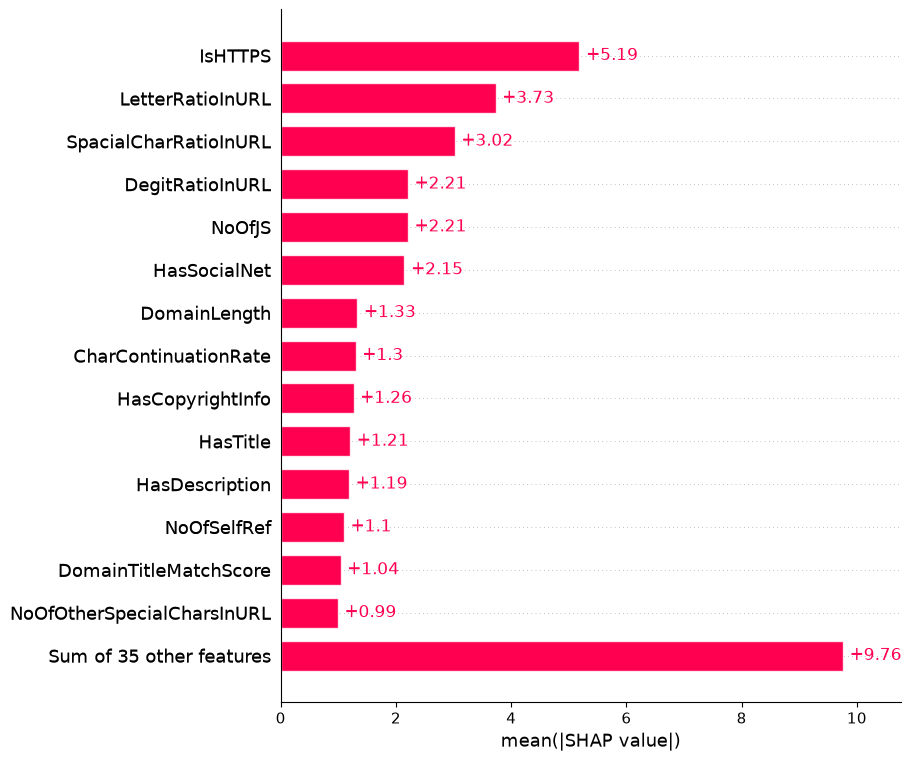

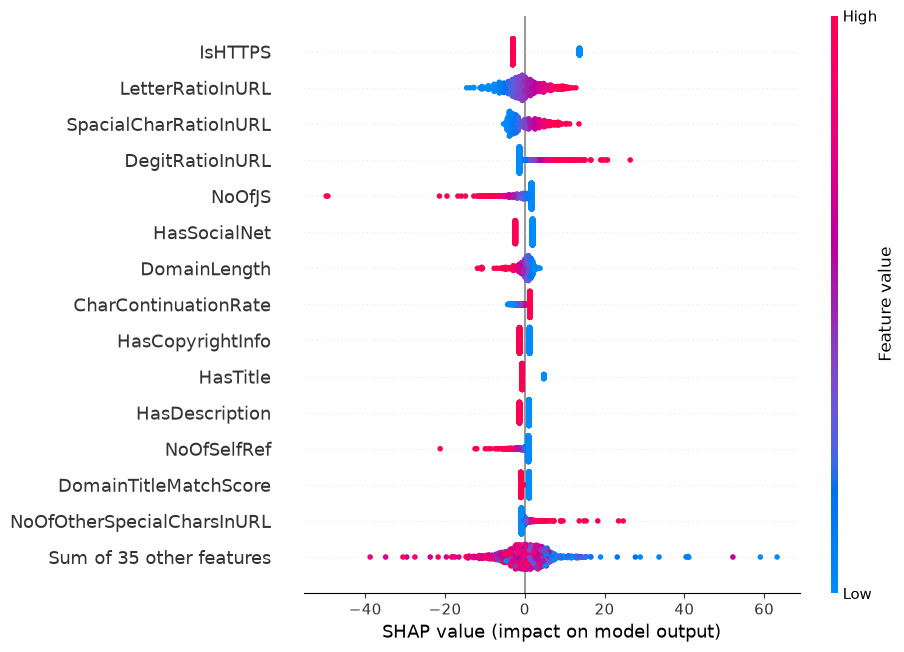

In [25]:
# EXERCISE 8: Computing SHAP Values and Global Importance Plots (1,000 Test URLs)
X_test_sample = X_test_scaled.iloc[:1000]

### START CODE HERE ### (≈ 2 lines of code)
explainer = shap.LinearExplainer(model_l2, X_train_scaled)
shap_values = explainer(X_test_sample)
### END CODE HERE ###

# 1. Global Mean Absolute SHAP Importance (Bar Plot)
shap.plots.bar(shap_values, max_display=15)

# 2. Global Directional Impact (Beeswarm Plot)
shap.plots.beeswarm(shap_values, max_display=15)

---
### 5.2 Local SOC Alert Triage: TP, TN, and FP Waterfall Plots (Exercise 9)

We locate the first **True Positive (TP)**, **True Negative (TN)**, and **False Positive (FP — False Alarm)** in our 1,000-URL test sample and inspect their local SHAP Waterfall plots (`max_display=10`), passing unscaled `X_test` values in `data=` so SOC analysts can read actual URL metrics.

### Exercise 9

=== CASE 1: TRUE POSITIVE (Confirmed Phishing Attack Caught) (Sample Index=2) | True Label=1 | P(Phishing)=99.99% ===


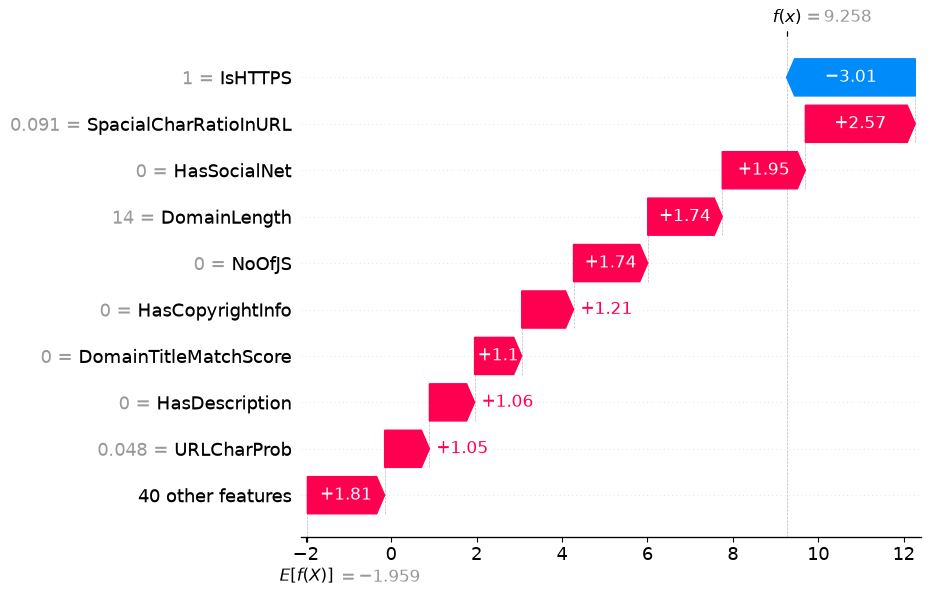

=== CASE 2: TRUE NEGATIVE (Legitimate Traffic Correctly Cleared) (Sample Index=0) | True Label=0 | P(Phishing)=0.00% ===


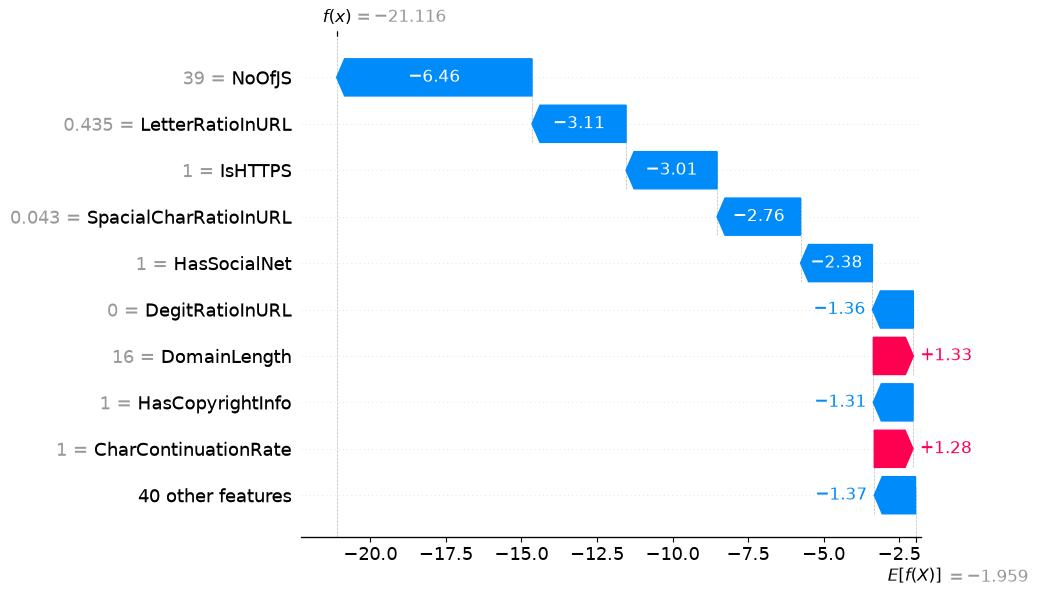

=== CASE 3: FALSE POSITIVE (Legitimate Site Wrongly Flagged — False Alarm) (Sample Index=330) | True Label=0 | P(Phishing)=31.58% ===


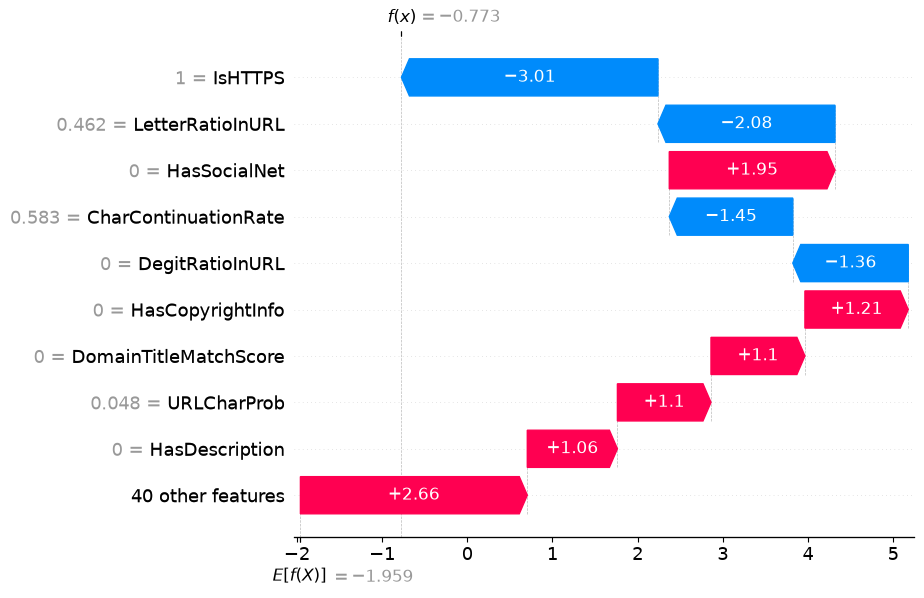

In [26]:
# EXERCISE 9: Local SOC Triage of TP, TN, and FP Cases with SHAP Waterfall
y_test_sample = y_test.iloc[:1000].values
y_prob_sample = model_l2.predict_proba(X_test_sample)[:, 1]
y_pred_sample = (y_prob_sample >= 0.50).astype(int)

### START CODE HERE ### (≈ 3 lines of code)
tp_candidates = np.where((y_test_sample == 1) & (y_pred_sample == 1))[0]
tn_candidates = np.where((y_test_sample == 0) & (y_pred_sample == 0))[0]
fp_candidates = np.where((y_test_sample == 0) & (y_pred_sample == 1))[0]
tp_idx = int(tp_candidates[0]) if len(tp_candidates) else 0
tn_idx = int(tn_candidates[0]) if len(tn_candidates) else 0
### END CODE HERE ###

fp_idx = int(fp_candidates[0]) if len(fp_candidates) > 0 else int(np.argmax(y_prob_sample * (y_test_sample == 0)))

def plot_soc_waterfall(idx, case_title):
    print(f"=== {case_title} (Sample Index={idx}) | True Label={y_test_sample[idx]} | P(Phishing)={y_prob_sample[idx]*100:.2f}% ===")
    local_exp = shap.Explanation(
        values=shap_values.values[idx],
        base_values=float(np.ravel(shap_values.base_values)[idx]),
        data=X_test.iloc[idx].values, # Unscaled values for human analyst readability
        feature_names=X.columns
    )
    shap.plots.waterfall(local_exp, max_display=10)

plot_soc_waterfall(tp_idx, "CASE 1: TRUE POSITIVE (Confirmed Phishing Attack Caught)")
plot_soc_waterfall(tn_idx, "CASE 2: TRUE NEGATIVE (Legitimate Traffic Correctly Cleared)")
plot_soc_waterfall(fp_idx, "CASE 3: FALSE POSITIVE (Legitimate Site Wrongly Flagged — False Alarm)")

In [27]:
# FP explanation helper: list the strongest local contributions toward the phishing prediction.
fp_local = shap_values[fp_idx]
fp_contrib = pd.DataFrame({
    'Feature': X.columns,
    'SHAP_Value': fp_local.values,
    'Raw_Value': X_test.iloc[fp_idx].values
}).sort_values('SHAP_Value', ascending=False)
print('Top features pushing this false positive toward PHISHING:')
display(fp_contrib.head(3).round(4))

Top features pushing this false positive toward PHISHING:


,Feature,SHAP_Value,Raw_Value
35,HasSocialNet,1.9456,0.0
42,HasCopyrightInfo,1.2132,0.0
24,DomainTitleMatchScore,1.1028,0.0


---
### 5.3 Operational Decision Threshold Tuning ($\tau \in \{0.20, 0.50, 0.85\}$) (Exercise 10)

We evaluate `model_l2` (`M3`) on the full test set across three operational decision thresholds:
* **$\tau = 0.20$ (Threat Hunting Mode):** Maximizes Recall to catch stealthy phishing campaigns.
* **$\tau = 0.50$ (Default Mode):** Balanced threshold.
* **$\tau = 0.85$ (Automated Firewall Blocking Mode):** Maximizes Precision and minimizes False Positives to prevent blocking legitimate business traffic.

### Exercise 10

In [28]:
# EXERCISE 10: Comparing Operational Decision Thresholds (0.20, 0.50, 0.85)
y_prob_full = model_l2.predict_proba(X_test_scaled)[:, 1]
thresholds = [0.20, 0.50, 0.85]
threshold_records = []

for tau in thresholds:
    ### START CODE HERE ### (≈ 2 lines of code)
    y_pred_tau = (y_prob_full >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_tau).ravel()
    ### END CODE HERE ###

    threshold_records.append({
        "Threshold (tau)": tau,
        "SOC Operational Mode": "Threat Hunting" if tau == 0.20 else ("Default" if tau == 0.50 else "Automated Blocking"),
        "Precision": round(precision_score(y_test, y_pred_tau), 4),
        "Recall (TPR)": round(recall_score(y_test, y_pred_tau), 4),
        "F1-Score": round(f1_score(y_test, y_pred_tau), 4),
        "True Positives (TP)": int(tp),
        "True Negatives (TN)": int(tn),
        "False Positives (FP)": int(fp),
        "False Negatives (FN)": int(fn)
    })

threshold_df = pd.DataFrame(threshold_records)
display(threshold_df)

,Threshold (tau),SOC Operational Mode,Precision,Recall (TPR),F1-Score,True Positives (TP),True Negatives (TN),False Positives (FP),False Negatives (FN)
0,0.20,Threat Hunting,0.9988,0.9994,0.9991,25221,33682,31,15
1,0.50,Default,0.9996,0.9989,0.9992,25208,33703,10,28
2,0.85,Automated Blocking,1.0000,0.9975,0.9987,25172,33713,0,64


---
### 💡 Part 4 Reflection Questions

1. A global weight `w_j` is one learned coefficient shared across all URLs; it describes the model's overall direction and strength for feature `j` (on standardized inputs). A local SHAP value `φ_j(x)` explains how feature `j` contributes to the prediction of one particular URL, relative to the explainer's baseline.

2. The specific 2–3 features responsible for the selected false positive are the largest positive contributors in that URL's FP Waterfall plot. Inspect the FP plot immediately above and name the features with the largest positive SHAP values; these are case-specific and should not be guessed in advance.

3. A high threshold such as 0.85 favors precision before automated blocking, reducing the risk of blocking legitimate websites. Scores from 0.20 to 0.85 can be sent to human analysts for contextual review, while the lower threshold 0.20 is useful for threat hunting because it captures more possible attacks at the cost of more false alarms.

## 6 - Conclusion & SOC Engineering Synthesis (Deliverable Solution)

> ### 🛡️ SOC Engineering Synthesis Report
> 1. **Hyperparameter & Sparsity Trade-Off:** Use `results_df` to select the model with the best balance of Precision, Recall, F1, PR-AUC, FP/FN and sparsity. M4 (L1, C=0.01) is the sparse candidate; its zeroed coefficient count is reported in the comparison table. Do not choose a model based on accuracy alone.
>
> 2. **Global Interpretability (Odds Ratios & SHAP):** The strongest phishing and benign indicators are identified by the positive/negative L2 coefficients in `weights_df` and by mean absolute SHAP importance in the global bar plot. Odds Ratios above 1 increase phishing odds; values below 1 decrease them.
>
> 3. **SOC Alert Triage & Dual-Threshold Policy:** Use the FP Waterfall plot to identify the features that pushed the selected legitimate URL above the alert threshold. The three threshold results in `threshold_df` quantify the operational trade-off.
> * *False Positive Triage Note (3 sentences):* The selected FP is a legitimate URL incorrectly classified as phishing at the default threshold. Its Waterfall plot identifies the feature contributions that pushed the model output toward phishing; the largest positive SHAP contributions should be reviewed by the analyst. This alert should be investigated rather than automatically blocked, and the model should be monitored for similar false alarms.
>
> * *Recommended Threshold Policy:* `τ = 0.20` for broad threat hunting and analyst review; `τ = 0.50` for the default classification; `τ = 0.85` for high-confidence automated blocking, subject to validation against the FP/FN counts in `threshold_df`.

In [29]:
# Data-driven SOC synthesis summary (generated after all exercises have run)
best_f1_row = results_df.loc[results_df['F1-Score'].idxmax()]
l1_row = results_df[results_df['Model'].str.startswith('M4:')].iloc[0]
print(f"Best F1 model: {best_f1_row['Model']} (F1={best_f1_row['F1-Score']:.4f}, Precision={best_f1_row['Precision']:.4f}, Recall={best_f1_row['Recall (TPR)']:.4f}, PR-AUC={best_f1_row['PR-AUC']:.4f}).")
print(f"M4 L1 sparsity: {l1_row['Zeroed Weights (Sparsity)']} zeroed weights out of {X.shape[1]} features.")
print('Review weights_df and SHAP global plots for the strongest global phishing/benign indicators.')
print('Review fp_contrib and the FP waterfall for the specific false-alarm explanation.')
print('Operational policy: 0.20 = threat-hunting/analyst queue; 0.50 = default; 0.85 = high-confidence automated blocking.')

Best F1 model: M1: Unregularized (None) (F1=0.9993, Precision=0.9996, Recall=0.9990, PR-AUC=1.0000).
M4 L1 sparsity: 24 / 49 zeroed weights out of 49 features.
Review weights_df and SHAP global plots for the strongest global phishing/benign indicators.
Review fp_contrib and the FP waterfall for the specific false-alarm explanation.
Operational policy: 0.20 = threat-hunting/analyst queue; 0.50 = default; 0.85 = high-confidence automated blocking.
